# 08 - Exercise 2: checks, final 3, Nashville comparison
Input: pool of 9 from notebook 07.

1. Red flags
2. Extra checks
3. Consistency (H2 2025)
4. Summary table
5. Nashville comparison
6. Market value and final 3
7. Acquisition table
8. Pizza charts
9. Coach's numbers

## Setup

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mplsoccer import PyPizza

pd.set_option("display.max_columns", 50)

PROCESSED_FOLDER = Path("../../data/processed")
FIGURES_FOLDER = Path("../../figures")

BALL_WINNING_COLOR = "#2a78d6"   # blue
PROGRESSION_COLOR = "#1baf7a"    # aqua
CHECK_COLOR = "#9a9890"          # grey = extra check, not in the score
NASHVILLE_COLOR = "#eda100"      # gold
POOL_COLOR = "#2a78d6"
PEER_COLOR = "#c3c2b7"
BACKGROUND = "#fcfcfb"
TEXT_COLOR = "#0b0b0b"
TEXT_MUTED = "#52514e"
GRID_COLOR = "#e4e3df"

RED_FLAG_PERCENTILE = 25      # bottom 25%

In [2]:
peer_group = pd.read_parquet(PROCESSED_FOLDER / "ex2_peer_group_scored.parquet")
pool = pd.read_parquet(PROCESSED_FOLDER / "ex2_pool.parquet")
mls_h2_2025 = pd.read_parquet(PROCESSED_FOLDER / "asa_players_2025_h2.parquet")

print("Peer group:", len(peer_group), "| Pool:", len(pool))
pool[["player_name", "current_team", "score", "ball_winning_score", "progression_score"]].round(1)

Peer group: 93 | Pool: 9


,player_name,current_team,score,ball_winning_score,progression_score
3,Kai Trewin,New York City FC,83.3,86.6,78.2
457,Yannick Bright,Inter Miami CF,76.2,91.8,53.0
551,Owen Gene,Minnesota United FC,74.1,77.3,69.2
574,Matti Peltola,D.C. United,69.8,74.9,62.1
184,Taha Habroune,Columbus Crew,63.2,71.0,51.5
295,Adri Mehmeti,New York Red Bulls,62.7,50.4,81.0
525,Jovan Lukić,Philadelphia Union,61.9,71.7,47.2
666,Gerardo Valenzuela,FC Cincinnati,54.9,60.5,46.5
613,Nectarios Triantis,Minnesota United FC,52.7,56.7,46.8


In [3]:
WEIGHTS = {
    "interrupting_gplus_p96": 0.35,
    "interrupting_actions_p96": 0.15,
    "fouling_gplus_p96": 0.10,
    "passing_gplus_p96": 0.15,
    "avg_vertical_distance_yds": 0.10,
    "passes_completed_over_expected_p100": 0.10,
    "receiving_gplus_p96": 0.05,
}
BALL_WINNING_METRICS = ["interrupting_gplus_p96", "interrupting_actions_p96", "fouling_gplus_p96"]
PROGRESSION_METRICS = ["passing_gplus_p96", "avg_vertical_distance_yds",
                       "passes_completed_over_expected_p100", "receiving_gplus_p96"]
METRIC_LABELS = {
    "interrupting_gplus_p96": "ball-winning quality",
    "interrupting_actions_p96": "defensive volume",
    "fouling_gplus_p96": "foul balance",
    "passing_gplus_p96": "passing value",
    "avg_vertical_distance_yds": "forward passing",
    "passes_completed_over_expected_p100": "pass security",
    "receiving_gplus_p96": "receiving",
}

## 1 - Red flags
Score metrics in the bottom 25% of the peer group.

In [4]:
def red_flags(row):
    flags = []
    for metric in WEIGHTS:
        percentile = row[f"{metric}_pct"]
        if percentile < RED_FLAG_PERCENTILE:
            flags.append(f"{METRIC_LABELS[metric]} ({percentile:.0f}th)")
    return flags

pool["score_red_flags"] = pool.apply(red_flags, axis=1)

for index, row in pool.iterrows():
    if len(row["score_red_flags"]) == 0:
        flags_text = "none"
    else:
        flags_text = ", ".join(row["score_red_flags"])
    print(f"{row['player_name']}: {flags_text}")

Kai Trewin: receiving (4th)
Yannick Bright: none
Owen Gene: receiving (24th)
Matti Peltola: receiving (1th)
Taha Habroune: forward passing (12th)
Adri Mehmeti: none
Jovan Lukić: receiving (16th)
Gerardo Valenzuela: defensive volume (5th), forward passing (9th)
Nectarios Triantis: foul balance (14th), pass security (22th)


## 2 - Extra checks (not in the score)
- Ball losses: dribbling g+ per 96 (includes being dispossessed). Losses in midfield lead to counters. Flag if bottom 25%.
- Involvement: share of team touches. Does the team play through him? Flag if bottom 25%.

Minutes are handled by the 1,200-minute cut-off only, not as a warning.

In [5]:
peer_group["dribbling_gplus_p96"] = peer_group["gplus_dribbling"] / peer_group["minutes_played"] * 96

peer_group["dribbling_gplus_p96_pct"] = peer_group["dribbling_gplus_p96"].rank(pct=True) * 100
peer_group["share_team_touches_pct"] = peer_group["share_team_touches"].rank(pct=True) * 100

# copy the new percentiles onto the pool rows (matched by player_id)
extra_columns = ["player_id", "dribbling_gplus_p96_pct", "share_team_touches_pct"]
pool = pool.merge(peer_group[extra_columns], on="player_id", how="left")

pool[["player_name", "dribbling_gplus_p96_pct", "share_team_touches_pct", "minutes_played"]].round(0)

,player_name,dribbling_gplus_p96_pct,share_team_touches_pct,minutes_played
0,Kai Trewin,6.0,89.0,1402
1,Yannick Bright,44.0,83.0,2257
2,Owen Gene,68.0,47.0,2409
3,Matti Peltola,24.0,41.0,2487
4,Taha Habroune,95.0,45.0,2670
5,Adri Mehmeti,12.0,90.0,2845
6,Jovan Lukić,39.0,71.0,2763
7,Gerardo Valenzuela,22.0,34.0,1938
8,Nectarios Triantis,54.0,35.0,2019


## 3 - Consistency: H2 2025
1 Jul – 31 Dec 2025. Comparison group = midfielders with 600+ minutes. Percentile = share of that group at or below the player. Under 600 minutes = small sample.

In [6]:
h2_peers = mls_h2_2025[mls_h2_2025["general_position"].isin(["CM", "DM"]) & (mls_h2_2025["minutes_played"] >= 600)].copy()
print("2025 H2 comparison group:", len(h2_peers))

def add_per_96(table):
    table["interrupting_gplus_p96"] = table["gplus_interrupting"] / table["minutes_played"] * 96
    table["interrupting_actions_p96"] = table["actions_interrupting"] / table["minutes_played"] * 96
    table["fouling_gplus_p96"] = table["gplus_fouling"] / table["minutes_played"] * 96
    table["passing_gplus_p96"] = table["gplus_passing"] / table["minutes_played"] * 96
    table["receiving_gplus_p96"] = table["gplus_receiving"] / table["minutes_played"] * 96
    return table

h2_peers = add_per_96(h2_peers)
h2_all = add_per_96(mls_h2_2025.copy())

2025 H2 comparison group: 85


In [7]:
def percentile_vs_peers(value, peer_values):
    # share of the group at or below this value
    return (peer_values <= value).mean() * 100

def h2_sub_score(player_row, metrics):
    group_weight = sum(WEIGHTS[metric] for metric in metrics)
    total = 0.0
    for metric in metrics:
        total += percentile_vs_peers(player_row[metric], h2_peers[metric]) * WEIGHTS[metric]
    return total / group_weight

In [8]:
consistency_rows = []

for index, row in pool.iterrows():
    match = h2_all[h2_all["player_id"] == row["player_id"]]

    if len(match) == 0:
        consistency_rows.append({"player_id": row["player_id"], "h2_2025_minutes": 0,
                                 "h2_ball_winning": np.nan, "h2_progression": np.nan})
        continue

    h2_row = match.iloc[0]
    consistency_rows.append({
        "player_id": row["player_id"],
        "h2_2025_minutes": h2_row["minutes_played"],
        "h2_ball_winning": h2_sub_score(h2_row, BALL_WINNING_METRICS),
        "h2_progression": h2_sub_score(h2_row, PROGRESSION_METRICS),
    })

consistency = pd.DataFrame(consistency_rows)
pool = pool.merge(consistency, on="player_id", how="left")

pool[["player_name", "ball_winning_score", "h2_ball_winning", "progression_score", "h2_progression",
      "h2_2025_minutes"]].round(0)

,player_name,ball_winning_score,h2_ball_winning,progression_score,h2_progression,h2_2025_minutes
0,Kai Trewin,87.0,NaN,78.0,NaN,0
1,Yannick Bright,92.0,92.0,53.0,19.0,753
2,Owen Gene,77.0,92.0,69.0,68.0,360
3,Matti Peltola,75.0,82.0,62.0,22.0,1020
4,Taha Habroune,71.0,53.0,51.0,50.0,742
5,Adri Mehmeti,50.0,NaN,81.0,NaN,0
6,Jovan Lukić,72.0,38.0,47.0,40.0,1423
7,Gerardo Valenzuela,60.0,35.0,47.0,19.0,435
8,Nectarios Triantis,57.0,68.0,47.0,43.0,797


Similar sub-scores = consistent. A big jump in 2026 = breakthrough season, less proven.

## 4 - Summary table
"warning" when:
- Ball-winning / Progression: any metric in the bottom 25%
- Ball losses / Involvement: bottom 25%
- Consistency 2025: ball-winning < 50 or progression < 45 ("too few minutes" = under 600 minutes or not in MLS)

In [9]:
def group_check(row, metrics):
    for metric in metrics:
        if row[f"{metric}_pct"] < RED_FLAG_PERCENTILE:
            return "warning"
    return "ok"

def threshold_check(value, limit):
    if value < limit:
        return "warning"
    return "ok"

def consistency_check(row):
    if row["h2_2025_minutes"] < 600:
        return "too few minutes"
    if row["h2_ball_winning"] < 50 or row["h2_progression"] < 45:
        return "warning"
    return "ok"

In [10]:
summary = pd.DataFrame({"player": pool["player_name"], "club": pool["current_team"], "score": pool["score"].round(1)})

summary["Ball-winning"] = pool.apply(group_check, axis=1, metrics=BALL_WINNING_METRICS)
summary["Progression"] = pool.apply(group_check, axis=1, metrics=PROGRESSION_METRICS)
summary["Ball losses"] = pool["dribbling_gplus_p96_pct"].apply(threshold_check, limit=RED_FLAG_PERCENTILE)
summary["Involvement"] = pool["share_team_touches_pct"].apply(threshold_check, limit=RED_FLAG_PERCENTILE)
summary["Consistency 2025"] = pool.apply(consistency_check, axis=1)

check_columns = ["Ball-winning", "Progression", "Ball losses", "Involvement", "Consistency 2025"]
summary["warnings"] = (summary[check_columns] == "warning").sum(axis=1)
summary

,player,club,score,Ball-winning,Progression,Ball losses,Involvement,Consistency 2025,warnings
0,Kai Trewin,New York City FC,83.3,ok,warning,warning,ok,too few minutes,2
1,Yannick Bright,Inter Miami CF,76.2,ok,ok,ok,ok,warning,1
2,Owen Gene,Minnesota United FC,74.1,ok,warning,ok,ok,too few minutes,1
3,Matti Peltola,D.C. United,69.8,ok,warning,warning,ok,warning,3
4,Taha Habroune,Columbus Crew,63.2,ok,warning,ok,ok,ok,1
5,Adri Mehmeti,New York Red Bulls,62.7,ok,ok,warning,ok,too few minutes,1
6,Jovan Lukić,Philadelphia Union,61.9,ok,warning,ok,ok,warning,2
7,Gerardo Valenzuela,FC Cincinnati,54.9,warning,warning,warning,ok,too few minutes,3
8,Nectarios Triantis,Minnesota United FC,52.7,warning,warning,ok,ok,warning,3


A warning needs explaining, not an automatic no (e.g. low receiving is common for deep 6s).

## 5 - Nashville comparison
Nashville's midfielders with 1,200+ minutes are already in the peer group.

In [11]:
nashville_midfielders = peer_group[peer_group["played_for_nashville"]].copy()
nashville_midfielders[["player_name", "age", "minutes_played", "score", "ball_winning_score",
                       "progression_score"]].round(1)

,player_name,age,minutes_played,score,ball_winning_score,progression_score
153,Patrick Yazbek,24.6,1667,47.7,57.3,33.2
317,Matthew Corcoran,20.7,2412,35.2,30.5,42.2
452,Edvard Tagseth,25.8,1900,34.0,39.2,26.1


In [12]:
# league medians (peer group of 93) to compare with
print(f"MLS median ball-winning score: {peer_group['ball_winning_score'].median():.0f}")
print(f"MLS median progression score:  {peer_group['progression_score'].median():.0f}")

MLS median ball-winning score: 50
MLS median progression score:  52


In [13]:
comparison_columns = ["player_name", "score", "ball_winning_score", "progression_score"]

nashville_part = nashville_midfielders[comparison_columns].copy()
nashville_part["group"] = "Nashville (current)"
pool_part = pool[comparison_columns].copy()
pool_part["group"] = "Candidate"

comparison = pd.concat([nashville_part, pool_part])
comparison.sort_values("score", ascending=False).round(1)

,player_name,score,ball_winning_score,progression_score,group
0,Kai Trewin,83.3,86.6,78.2,Candidate
1,Yannick Bright,76.2,91.8,53.0,Candidate
2,Owen Gene,74.1,77.3,69.2,Candidate
3,Matti Peltola,69.8,74.9,62.1,Candidate
4,Taha Habroune,63.2,71.0,51.5,Candidate
5,Adri Mehmeti,62.7,50.4,81.0,Candidate
6,Jovan Lukić,61.9,71.7,47.2,Candidate
7,Gerardo Valenzuela,54.9,60.5,46.5,Candidate
8,Nectarios Triantis,52.7,56.7,46.8,Candidate
153,Patrick Yazbek,47.7,57.3,33.2,Nashville (current)


Nashville midfielders in gold

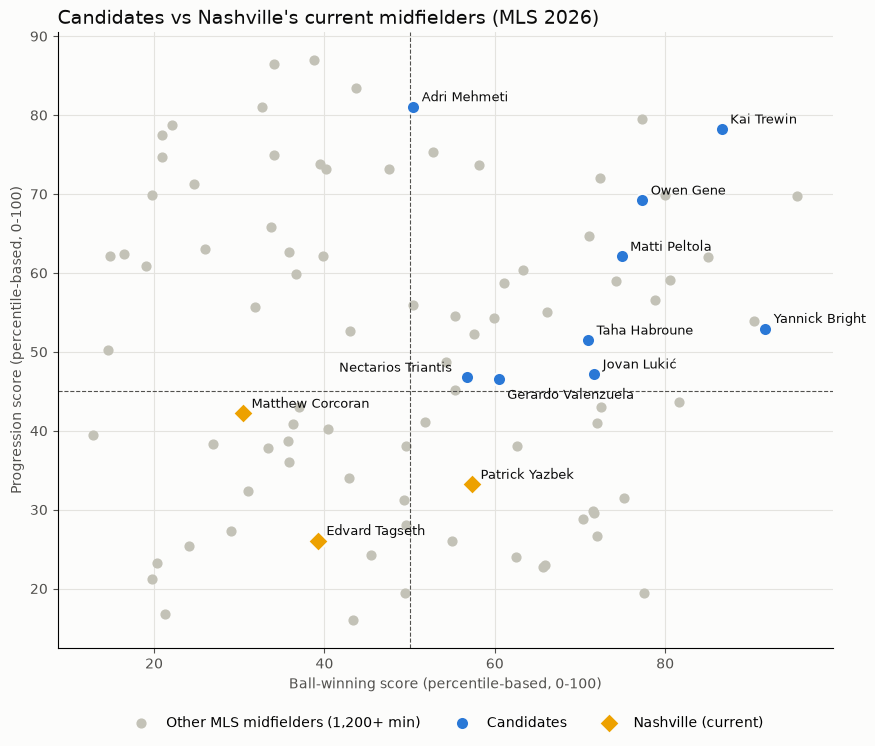

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))
fig.set_facecolor(BACKGROUND)
ax.set_facecolor(BACKGROUND)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(colors=TEXT_MUTED)
ax.grid(color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)

highlighted_ids = set(pool["player_id"]) | set(nashville_midfielders["player_id"])
others = peer_group[~peer_group["player_id"].isin(highlighted_ids)]

ax.scatter(others["ball_winning_score"], others["progression_score"], s=40, color=PEER_COLOR,
           label="Other MLS midfielders (1,200+ min)")
ax.scatter(pool["ball_winning_score"], pool["progression_score"], s=90, color=POOL_COLOR,
           edgecolor=BACKGROUND, linewidth=1.5, label="Candidates", zorder=3)
ax.scatter(nashville_midfielders["ball_winning_score"], nashville_midfielders["progression_score"], s=110,
           marker="D", color=NASHVILLE_COLOR, edgecolor=BACKGROUND, linewidth=1.5,
           label="Nashville (current)", zorder=3)

# label offsets for close neighbours
LABEL_OFFSETS = {
    "Nectarios Triantis": (-92, 4),
    "Gerardo Valenzuela": (6, -14),
}
labelled = pd.concat([pool, nashville_midfielders])
for index, row in labelled.iterrows():
    offset = LABEL_OFFSETS.get(row["player_name"], (6, 4))
    ax.annotate(row["player_name"], (row["ball_winning_score"], row["progression_score"]),
                xytext=offset, textcoords="offset points", fontsize=9, color=TEXT_COLOR)

ax.axvline(50, color=TEXT_MUTED, linewidth=0.8, linestyle="--")
ax.axhline(45, color=TEXT_MUTED, linewidth=0.8, linestyle="--")
ax.set_xlabel("Ball-winning score (percentile-based, 0-100)", color=TEXT_MUTED)
ax.set_ylabel("Progression score (percentile-based, 0-100)", color=TEXT_MUTED)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3)
ax.set_title("Candidates vs Nashville's current midfielders (MLS 2026)", fontsize=14, color=TEXT_COLOR, loc="left")

fig.savefig(FIGURES_FOLDER / "ex2_scatter_with_nashville.png", dpi=200, bbox_inches="tight")
plt.show()

## 6 - Market value and final 3
Transfermarkt values and contracts entered by hand (12 Nov 2026) in the pool CSV from notebook 07.

Assumption: moves within MLS are trades, not transfer fees, so market value is a proxy for acquisition difficulty, cost and resale. Salary = budget impact.

In [15]:
transfermarkt = pd.read_csv(PROCESSED_FOLDER / "ex2_pool_for_transfermarkt.csv")
transfermarkt["contract_until"] = pd.to_datetime(transfermarkt["contract_until"])

transfermarkt_columns = transfermarkt[["player_name", "market_value_eur", "contract_until"]]
pool = pool.merge(transfermarkt_columns, on="player_name", how="left")

print("Players missing a market value:", pool["market_value_eur"].isna().sum())

Players missing a market value: 0


Final 3 rule:
1. Market value ≤ €7M
2. At most 1 warning
3. Highest score

High score but more warnings = one to monitor.

In [16]:
MAX_MARKET_VALUE = 7_000_000
MAX_WARNINGS = 1

pool["warnings"] = summary["warnings"].values          # same row order as the summary table
pool["within_budget"] = pool["market_value_eur"] <= MAX_MARKET_VALUE
pool["few_warnings"] = pool["warnings"] <= MAX_WARNINGS

eligible = pool[pool["within_budget"] & pool["few_warnings"]].sort_values("score", ascending=False)
final_3 = eligible.head(3)

print("Final 3:", final_3["player_name"].tolist())

Final 3: ['Yannick Bright', 'Owen Gene', 'Taha Habroune']


In [17]:
# who didn't make it, and why
lowest_final_score = final_3["score"].min()

def status(row):
    if row["player_name"] in final_3["player_name"].tolist():
        return "Final 3"
    if not row["within_budget"]:
        return "Above budget"
    # high enough score to make the final 3, but too many warnings
    if row["score"] > lowest_final_score:
        return "One to monitor (" + str(row["warnings"]) + " warnings)"
    return "Not selected (" + str(row["warnings"]) + " warnings)"

pool["status"] = pool.apply(status, axis=1)
pool[["player_name", "score", "warnings", "market_value_eur", "status"]].sort_values("score", ascending=False)

,player_name,score,warnings,market_value_eur,status
0,Kai Trewin,83.279570,2,1800000,One to monitor (2 warnings)
1,Yannick Bright,76.236559,1,2000000,Final 3
2,Owen Gene,74.086022,1,1500000,Final 3
3,Matti Peltola,69.784946,3,1500000,One to monitor (3 warnings)
4,Taha Habroune,63.172043,1,5000000,Final 3
5,Adri Mehmeti,62.688172,1,8000000,Above budget
6,Jovan Lukić,61.881720,2,5000000,Not selected (2 warnings)
7,Gerardo Valenzuela,54.892473,3,2500000,Not selected (3 warnings)
8,Nectarios Triantis,52.741935,3,3500000,Not selected (3 warnings)


## 7 - Acquisition table
Salary (MLSPA via ASA), market value and contract end (Transfermarkt).

In [18]:
acquisition = pool.sort_values("score", ascending=False).copy()

acquisition_table = pd.DataFrame({
    "Player": acquisition["player_name"],
    "Club": acquisition["current_team"],
    "Age": acquisition["age"].astype(int),
    "Salary (USD)": acquisition["guaranteed_compensation"].map("${:,.0f}".format),
    "Market value (EUR)": (acquisition["market_value_eur"] / 1_000_000).map("€{:.1f}m".format),
    "Contract until": acquisition["contract_until"].dt.strftime("%b %Y"),
    "Status": acquisition["status"],
})
acquisition_table

,Player,Club,Age,Salary (USD),Market value (EUR),Contract until,Status
0,Kai Trewin,New York City FC,25,"$311,542",€1.8m,Jun 2029,One to monitor (2 warnings)
1,Yannick Bright,Inter Miami CF,25,"$464,192",€2.0m,Dec 2028,Final 3
2,Owen Gene,Minnesota United FC,23,"$450,100",€1.5m,Dec 2027,Final 3
3,Matti Peltola,D.C. United,24,"$876,000",€1.5m,Dec 2027,One to monitor (3 warnings)
4,Taha Habroune,Columbus Crew,20,"$152,000",€5.0m,Dec 2027,Final 3
5,Adri Mehmeti,New York Red Bulls,17,"$158,980",€8.0m,Dec 2028,Above budget
6,Jovan Lukić,Philadelphia Union,24,"$441,375",€5.0m,Jun 2029,Not selected (2 warnings)
7,Gerardo Valenzuela,FC Cincinnati,22,"$142,542",€2.5m,Dec 2026,Not selected (3 warnings)
8,Nectarios Triantis,Minnesota United FC,23,"$732,665",€3.5m,Dec 2029,Not selected (3 warnings)


## 8 - Pizza charts (final 3)
Percentiles vs peer group. Blue = ball-winning, aqua = progression, grey = ball security (extra check, not in the score). Ball security = percentile of dribbling g+ (higher = loses the ball less).

In [19]:
CHECK_METRICS = ["dribbling_gplus_p96"]
pizza_metrics = BALL_WINNING_METRICS + PROGRESSION_METRICS + CHECK_METRICS

pizza_label_names = dict(METRIC_LABELS)
pizza_label_names["dribbling_gplus_p96"] = "ball security"

pizza_labels = []
for metric in pizza_metrics:
    label = pizza_label_names[metric].capitalize()
    label = label.replace(" ", "\n", 1)          # "Ball-winning quality" -> two lines
    pizza_labels.append(label)

slice_colors = ([BALL_WINNING_COLOR] * len(BALL_WINNING_METRICS)
                + [PROGRESSION_COLOR] * len(PROGRESSION_METRICS)
                + [CHECK_COLOR] * len(CHECK_METRICS))

In [20]:
def draw_pizza(row):
    values = []
    for metric in pizza_metrics:
        values.append(int(round(row[f"{metric}_pct"])))

    pizza = PyPizza(params=pizza_labels, background_color=BACKGROUND, straight_line_color=GRID_COLOR,
                    last_circle_color=TEXT_MUTED, other_circle_color=GRID_COLOR, other_circle_ls="-",
                    straight_line_lw=1, last_circle_lw=1, other_circle_lw=1)

    fig, ax = pizza.make_pizza(
        values, figsize=(7, 7.5), slice_colors=slice_colors, value_colors=["#ffffff"] * len(values),
        value_bck_colors=slice_colors, blank_alpha=0.25, param_location=110,
        kwargs_slices=dict(edgecolor=BACKGROUND, linewidth=1.5, zorder=2),
        kwargs_params=dict(color=TEXT_COLOR, fontsize=10, va="center"),
        kwargs_values=dict(color="#ffffff", fontsize=10, zorder=3,
                           bbox=dict(edgecolor=BACKGROUND, boxstyle="round,pad=0.2", lw=1)),
    )
    fig.set_facecolor(BACKGROUND)

    title = f"{row['player_name']}, {row['current_team']}"
    age_in_years = int(row["age"])       # 23.6 -> 23
    subtitle = (f"Age {age_in_years}, {row['minutes_played']:,.0f} min (2026). "
                f"Percentile vs MLS midfielders (1,200+ min)")
    fig.text(0.5, 0.975, title, ha="center", fontsize=15, color=TEXT_COLOR)
    fig.text(0.5, 0.945, subtitle, ha="center", fontsize=9.5, color=TEXT_MUTED)
    fig.text(0.20, 0.025, "■ Winning the ball", color=BALL_WINNING_COLOR, fontsize=10, ha="center")
    fig.text(0.50, 0.025, "■ Progressing play", color=PROGRESSION_COLOR, fontsize=10, ha="center")
    fig.text(0.80, 0.025, "■ Ball security (not in score)", color=CHECK_COLOR, fontsize=10, ha="center")
    return fig

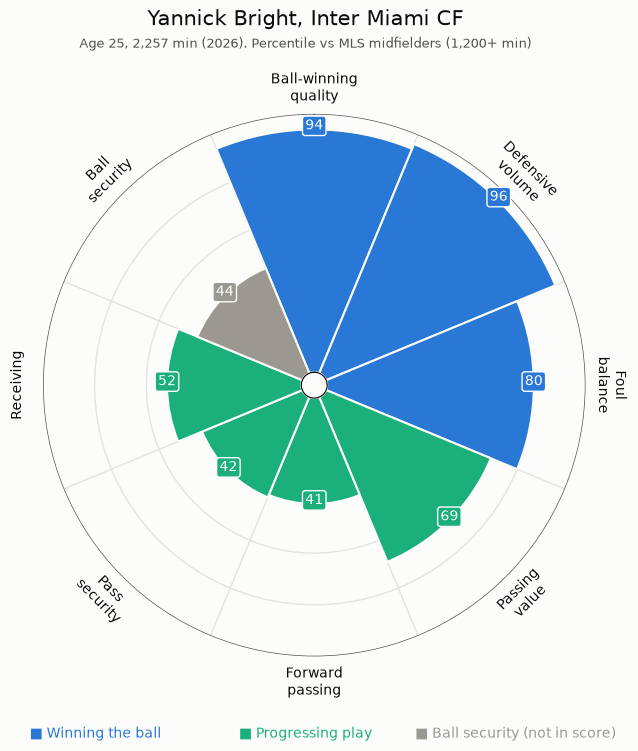

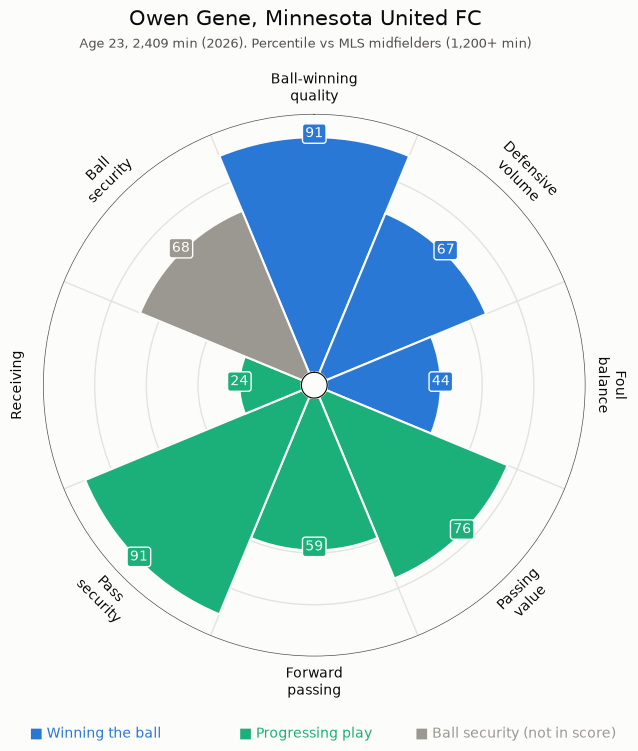

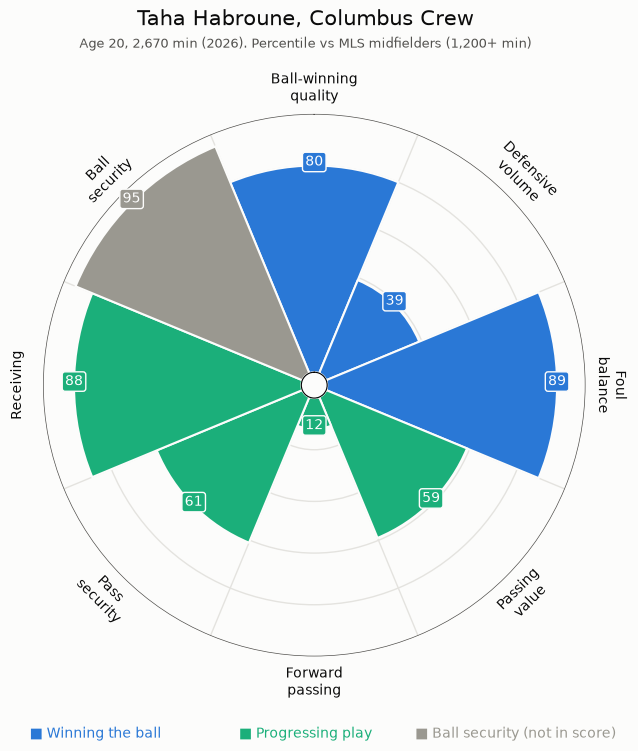

In [21]:
# one file per player
for index, row in final_3.iterrows():
    fig = draw_pizza(row)
    file_name = "ex2_pizza_" + row["player_name"].lower().replace(" ", "_") + ".png"
    fig.savefig(FIGURES_FOLDER / file_name, dpi=200, bbox_inches="tight")
    plt.show()

## 9 - Coach's numbers
Familiar numbers coaches ask about, not in the score. Final 3 vs the MLS median of the peer group (93 midfielders, 1,200+ min).
Per match = per 96 minutes (ASA standard).

In [22]:
peer_group["passes_p96"] = peer_group["attempted_passes"] / peer_group["minutes_played"] * 96
peer_group["key_passes_p96"] = peer_group["key_passes"] / peer_group["minutes_played"] * 96
peer_group["pass_completion"] = peer_group["pass_completion_percentage"] * 100
peer_group["expected_pass_completion"] = peer_group["xpass_completion_percentage"] * 100
# completed passes above what an average player would complete with the same passes, per 100 passes
peer_group["completion_above_expected"] = peer_group["pass_completion"] - peer_group["expected_pass_completion"]

COACH_NUMBERS = {
    "pass_completion": "Pass completion %",
    "expected_pass_completion": "Expected pass completion %",
    "completion_above_expected": "Above expected (per 100 passes)",
    "passes_p96": "Passes per match",
    "interrupting_actions_p96": "Defensive actions per match",
    "key_passes_p96": "Key passes per match",
}

final_3_names = ["Owen Gene", "Yannick Bright", "Taha Habroune"]
coach_table = pd.DataFrame(index=COACH_NUMBERS.values())
for name in final_3_names:
    player_row = peer_group[peer_group["player_name"] == name].iloc[0]
    coach_table[name] = [player_row[column] for column in COACH_NUMBERS]
coach_table["MLS median"] = [peer_group[column].median() for column in COACH_NUMBERS]
coach_table.round(1)

,Owen Gene,Yannick Bright,Taha Habroune,MLS median
Pass completion %,88.6,89.7,84.5,86.0
Expected pass completion %,85.2,88.4,82.5,84.9
Above expected (per 100 passes),3.4,1.3,2.0,1.7
Passes per match,49.9,60.3,49.9,49.9
Defensive actions per match,9.0,12.1,8.0,8.4
Key passes per match,0.8,0.8,1.7,0.8
